<a href="https://colab.research.google.com/github/IREStephen/ML-project-colab/blob/main/CampusDataSetProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Campus Dataset Project

Stephen Duffy, 2026

## Data Preperation

This section loads the campus and prepares it for analysis.

In [1]:
import pandas as pd

## Load the Dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv(
    '/content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv',
    skiprows=4
)

## CSV Conversion

In [4]:
# Load the Excel file (corrected file path)
excel_path = '/content/drive/MyDrive/CampusWalkDataset.xlsx'
xls = pd.ExcelFile(excel_path)

# Print the sheet names to understand the structure
print("Sheets in Excel:", xls.sheet_names)

# Read the first sheet (or specify sheet_name if needed)
df_excel = pd.read_excel(excel_path, sheet_name=0)

# Export to CSV
csv_path = '/content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv'
df_excel.to_csv(csv_path, index=False)
print(f"Successfully converted and saved to: {csv_path}")

Sheets in Excel: ['Sheet1', 'Lists']
Successfully converted and saved to: /content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## Inspect the data structure...

In [5]:
print("Column Names\n")
print(df.dtypes)

print("\nSample Names")
print(df.head())

Column Names

recorder_id                               object
date                                      object
location                                  object
weather                                   object
temperature_c                             object
sound level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                 object
other_sound_type_nature                   object
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
nature

## Cleaning the Data

In [6]:
# Start from df, which was already loaded with the correct header (skiprows=4)
clean_df = df.copy()

# Tidy column names and fix the 'ornnamental' typo from the Excel header
clean_df.columns = clean_df.columns.str.strip().str.replace(' ', '_')
clean_df = clean_df.rename(columns={'ornnamental_or_planted_plant_presence': 'ornamental_or_planted_plant_presence'})

# Drop rows that are completely empty
clean_df = clean_df.dropna(how='all')

# Keep only rows that hold a real observation (these key answers must be filled in)
key_cols = ['location', 'wellbeing_rating', 'stress_rating']
rows_before = len(clean_df)
clean_df = clean_df.dropna(subset=key_cols)
print(f"Rows removed for missing key answers: {rows_before - len(clean_df)}")

# Fill missing categorical answers with 'None' (nothing observed / nothing ticked)
fill_none_cols = [
    'primary_sound_type_urban', 'other_sound_type_urban',
    'primary_sound_type_nature', 'other_sound_type_nature',
    'native_or_wild_plant_presence', 'ornamental_or_planted_plant_presence',
    'moss_or_lichen_presence', 'trees_presence', 'other_notes'
]
missing_cols = [c for c in fill_none_cols if c not in clean_df.columns]
if missing_cols:
    print("Columns not found (check spelling):", missing_cols)
for col in fill_none_cols:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna('None')

# Standardise numeric columns
clean_df['temperature_c'] = pd.to_numeric(clean_df['temperature_c'], errors='coerce')
clean_df['insects_count'] = pd.to_numeric(clean_df['insects_count'], errors='coerce').fillna(0).astype(int)
clean_df['birds_count'] = pd.to_numeric(clean_df['birds_count'], errors='coerce').fillna(0).astype(int)

clean_df.reset_index(drop=True, inplace=True)

# Show every row and column
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

print(f"Cleaned dataset shape: {clean_df.shape}")
print("\nColumns that still have missing values:")
missing_report = clean_df.isna().sum()
print(missing_report[missing_report > 0])
display(clean_df)

Rows removed for missing key answers: 68
Cleaned dataset shape: (131, 23)

Columns that still have missing values:
temperature_c                  20
most_notable_nature_element    14
dtype: int64


,recorder_id,date,location,weather,temperature_c,sound_level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,2026-09-22 00:00:00,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,2026-09-22 00:00:00,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,2026-09-22 00:00:00,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None
5,R26_002,2026-09-22 00:00:00,L01 MainEntrance,Sunny,17.0,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,2026-09-22 00:00:00,L04 PathFrontiHub,Windy,17.0,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None
7,R26_002,2026-09-22 00:00:00,L05 GreenFrontSportsCentre,Sunny,19.0,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None
8,R26_002,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,Cloudy,16.0,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None
9,R26_002,2026-09-22 00:00:00,L07 CarParkNearSportsCentre,Sunny,18.0,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None


## Label Encoder

In [7]:
from sklearn.preprocessing import LabelEncoder

encoded_df = clean_df.copy()

# Turn each location name into a whole-number ID
le = LabelEncoder()
encoded_df['location_code'] = le.fit_transform(encoded_df['location'])

# Lookup table so every number can be traced back to a place
location_lookup = pd.DataFrame({
    'location_code': range(len(le.classes_)),
    'location': le.classes_
})
display(location_lookup)

,location_code,location
0,0,L01 MainEntrance
1,1,L02 LibraryGreen
2,2,L03 LowerSidePathiHub
3,3,L04 PathFrontiHub
4,4,L05 GreenFrontSportsCentre
5,5,L06 HedgingBehindSportsCentre
6,6,L07 CarParkNearSportsCentre
7,7,L08 AccessRoadNearSportsCentre


## Ordinal Encoding

In [8]:
# Order matters here, so the numbers are set by hand (keys are lower-case)
ordinal_maps = {
    'sound_level': {'quiet': 1, 'moderate': 2, 'loud': 3},
    'foot_traffic': {'low': 1, 'moderate': 2, 'high': 3},
    'trees_presence': {'none': 0, 'one or two': 1, 'many': 2},
    'native_or_wild_plant_presence': {'none': 0, 'some': 1, 'many': 2},
    'ornamental_or_planted_plant_presence': {'none': 0, 'some': 1, 'many': 2},
    'moss_or_lichen_presence': {'none': 0, 'some': 1, 'many': 2},
    # 1 = worst ... 5 = best
    'wellbeing_rating': {'very low wellbeing': 1, 'low wellbeing': 2, 'neutral': 3,
                         'positive wellbeing': 4, 'very positive wellbeing': 5},
    # 1 = very uneasy ... 5 = very easy (includes the typos found in the data)
    'ease_rating': {'very uneasy': 1, 'slightly uneasy': 2, 'slighly uneasy': 2,
                    'neutral': 3, 'easy': 4, 'very easy': 5, 'vey easy': 5},
    # 1 = very calm ... 5 = very stressful
    'stress_rating': {'very calm': 1, 'mostly calm': 2, 'neutral': 3,
                      'stressful': 4, 'very stressful': 5},
    # change in connection to nature
    'nature_connection_experience_rating': {'less connected': -1, 'no change': 0, 'same': 0,
                                            'a little more connected': 1, 'much more connected': 2},
}

for col, mapping in ordinal_maps.items():
    if col not in encoded_df.columns:
        print(f"Column not found: {col}")
        continue
    encoded_df[col + '_score'] = encoded_df[col].str.strip().str.lower().map(mapping)

# Safety check: report any answer that did not match the mapping
for col in ordinal_maps:
    if col + '_score' in encoded_df.columns:
        unmatched = encoded_df.loc[encoded_df[col + '_score'].isna(), col].unique()
        if len(unmatched) > 0:
            print(f"{col}: unmatched values -> {list(unmatched)}")
print("Mapping check finished")

Mapping check finished


# One Hot Encoder

In [9]:
nominal_cols = ['weather', 'primary_sound_type_urban', 'primary_sound_type_nature']

encoded_df = pd.get_dummies(
    encoded_df,
    columns=nominal_cols,
    prefix=['weather', 'urban_sound', 'nature_sound'],
    dtype=int
)

print(f"Encoded dataset shape: {encoded_df.shape}")
display(encoded_df.head())

Encoded dataset shape: (131, 47)


,recorder_id,date,location,temperature_c,sound_level,foot_traffic,other_sound_type_urban,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,location_code,sound_level_score,foot_traffic_score,trees_presence_score,native_or_wild_plant_presence_score,ornamental_or_planted_plant_presence_score,moss_or_lichen_presence_score,wellbeing_rating_score,ease_rating_score,stress_rating_score,nature_connection_experience_rating_score,weather_Cloudy,weather_Partly cloudy,weather_Sunny,weather_Windy,weather_sunny,urban_sound_Construction,urban_sound_Human voices,urban_sound_Other,urban_sound_Service machinery,urban_sound_Traffic,nature_sound_Insects,nature_sound_Other,nature_sound_Other birds,nature_sound_Seagulls,nature_sound_Trees,nature_sound_Wind
0,R26_001,2026-09-22 00:00:00,L01 MainEntrance,16.0,Quiet,Low,Traffic,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None,0,1,1,2,1,1,1,4,3,4,-1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1
1,R26_001,2026-09-22 00:00:00,L02 LibraryGreen,16.0,Moderate,Low,Human voices,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None,1,2,1,2,0,1,0,4,3,3,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1
2,R26_001,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,16.0,Quiet,Low,Traffic,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None,5,1,1,2,0,2,1,4,4,2,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1
3,R26_001,2026-09-22 00:00:00,L08 AccessRoadNearSportsCentre,16.0,Moderate,Low,Human voices,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None,7,2,1,1,1,0,1,4,3,3,2,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1
4,R26_001,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,16.0,Moderate,Low,Other,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None,5,2,1,1,0,1,0,4,4,2,-1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1


## Data Visualization: Comparing wellbeing_rate & stress_rating

I prompted Gemini to "Create a bar chart comparing wellbeing_rate and stress_rating" to compare human mood sets during the data gathering.
It gave an output of a well generated bar chart however the x axis values overlapped with eachother because of the width size of the chart. I did a small tweak with the value 8 and changed it to 12 in the plt.figure(figsize=(12, 6)) line.



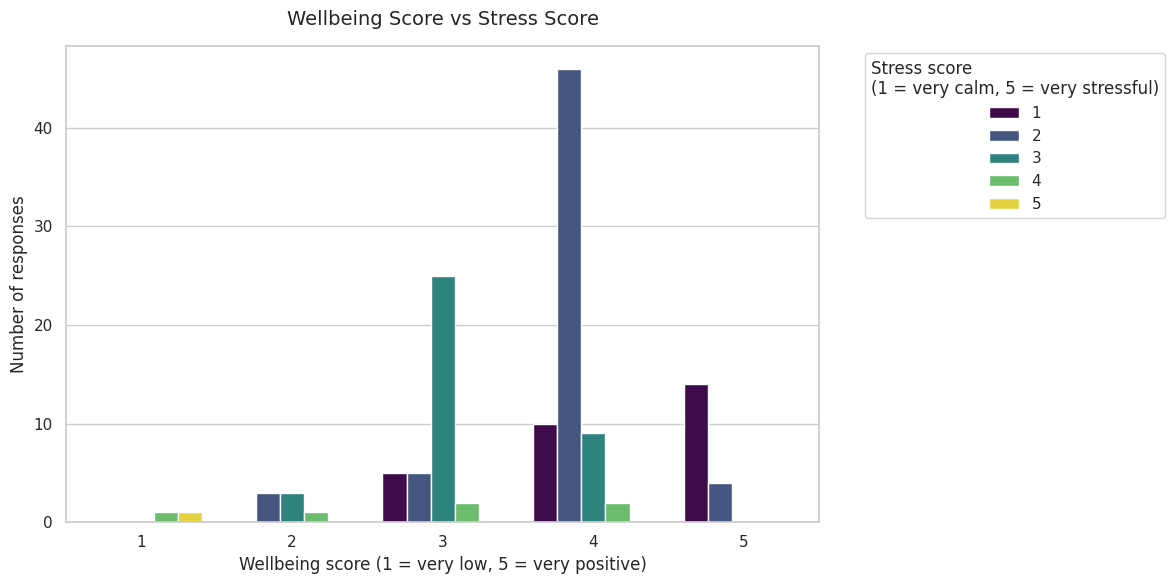

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

compare_df = (encoded_df
              .groupby(['wellbeing_rating_score', 'stress_rating_score'])
              .size().reset_index(name='count'))

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.barplot(data=compare_df, x='wellbeing_rating_score', y='count',
            hue='stress_rating_score', palette='viridis')

plt.title('Wellbeing Score vs Stress Score', fontsize=14, pad=15)
plt.xlabel('Wellbeing score (1 = very low, 5 = very positive)', fontsize=12)
plt.ylabel('Number of responses', fontsize=12)
plt.legend(title='Stress score\n(1 = very calm, 5 = very stressful)',
           bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Learning Process

The goal for this was do some data cleaning. What I wanted to do with the data set is give a table which then stores the values in an empty spot with its own header so everything is easier to visualise.

- I wanted to cut the empty cells after line 133.
- Have it where NaN or missing/unknown values gets set to "None".
- Structured like a table.
- Have all the data transferred from the csv file to collab using the python language.
- Learn the process and being able to articulate the code with the help of AI.

---

### 1. Dropping Empty Rows

To remove the cells where empty I used clean_df.dropna(how='all', inplace=True) and clean_df.reset_index(drop=True, inplace=True). So dropna(how='all') takes a look at my dataframe and removes all the empty cells for me. reset_index(drop=True) resets the (index) back to 0, meaning that (index) = to what ever numbers is. inplace=True means that the changes can happen in my clean_df.

---

### 2. Cleaning or Filling Missing Text

fill_none_cols = [
    'primary_sound_type_urban', 'other_sound_type_urban',
    'primary_sound_type_nature', 'other_sound_type_nature',
    'native_or_wild_plant_presence', 'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence', 'other_notes'
]
for col in fill_none_cols:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna('None') All this block of code just lists columns that records text like types of sound or plants that were observed. It loops back each column and uses this part called .fillna('None') to replace any empty cell with a 'None' string.

---

### 3. Standardizing the Numeric Columns

pd.to_numeric(['content'],errors='coerce') this line of code has the sole purpose of seeing what columns should have numbers in the cells then it converts them from object or string to all integers. Every typo or symbol just gets turned into an empty value which is now the 'NaN' value instead of giving weird errors. .fillna(0) just replaces the empty space with 0. .astype(int) makes sure that the insect and bird counts are all whole numbers so they cannot be floats because It shouldn't need specification with a decimal.

---

### 4. Trimming Specific Rows

clean_df = clean_df.drop(clean_df.index[134:199]) and clean_df.reset_index(drop=True, inplace=True) All this does is just cut the rows from 134 to 199, then resets the index numbering again.

---

### 5. Config Display Options

pd.set_option('display.max_rows', None) and pd.set_option('display.max_columns', None). These lines of code tells Pandas never to trim my table when visualising it as the table. This is because Pandas hides rows and columns with "..." if the dataset is too big to see. So setting that to 'None' makes sure that Colab shows everysingle row in the output.

# Data Exploration

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Columns used for exploration and modelling
env_cols = ['sound_level_score', 'foot_traffic_score', 'trees_presence_score', 'birds_count', 'insects_count']
exp_cols = ['wellbeing_rating_score', 'stress_rating_score', 'ease_rating_score', 'nature_connection_experience_rating_score']

# Summary statistics: count, mean, spread, min, quartiles, max
display(encoded_df[env_cols + exp_cols].describe().round(2))

,sound_level_score,foot_traffic_score,trees_presence_score,birds_count,insects_count,wellbeing_rating_score,stress_rating_score,ease_rating_score,nature_connection_experience_rating_score
count,131.00,131.00,131.00,131.00,131.00,131.00,131.00,131.00,131.00
mean,1.69,1.38,1.73,2.05,2.79,3.70,2.18,3.65,0.57
std,0.68,0.66,0.51,2.81,5.17,0.83,0.85,0.93,1.04
min,1.00,1.00,0.00,0.00,0.00,1.00,1.00,1.00,-1.00
25%,1.00,1.00,2.00,0.00,0.00,3.00,2.00,3.00,0.00
50%,2.00,1.00,2.00,1.00,1.00,4.00,2.00,4.00,1.00
75%,2.00,2.00,2.00,3.00,3.00,4.00,3.00,4.00,1.00
max,3.00,3.00,2.00,20.00,31.00,5.00,5.00,5.00,2.00


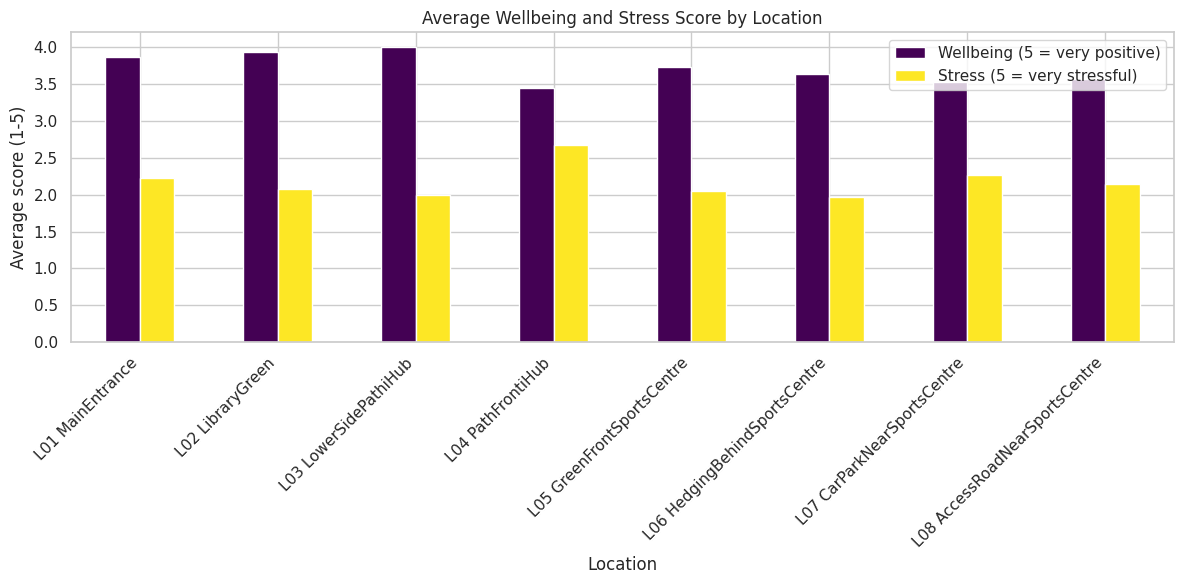

In [12]:
# Average wellbeing and stress at each location
by_location = encoded_df.groupby('location')[['wellbeing_rating_score', 'stress_rating_score']].mean()

by_location.plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Average Wellbeing and Stress Score by Location')
plt.xlabel('Location')
plt.ylabel('Average score (1-5)')
plt.xticks(rotation=45, ha='right')
plt.legend(['Wellbeing (5 = very positive)', 'Stress (5 = very stressful)'])
plt.tight_layout()
plt.show()

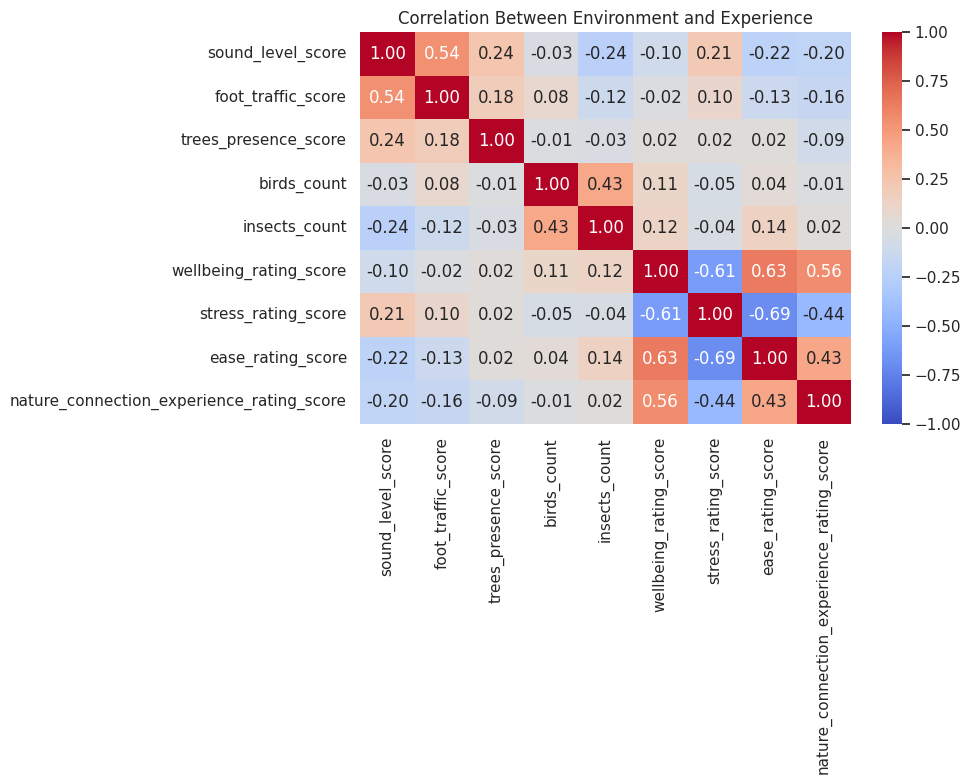

In [13]:
# Correlation between environment features and human experience (-1 to +1)
corr = encoded_df[env_cols + exp_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Between Environment and Experience')
plt.tight_layout()
plt.show()

## Learning Process: Data Exploration

env_cols and exp_cols are just lists of column names. And those names join two lists with + gives one list, so then encoded_df[env_cols + exp_cols] selects just those columns only.

---

.describe() gives the count number such as mean, standard deviation, min, quartiles and max for every selected column. .round(2) just keeps two decimals so it is readable. I had looked at the mean to see which of the typical score and the min & max to spot the odd values.

---

groupby('location')[...].mean() this line splits the rows into one group per location so then it averages the wellbeing and stress scores in each group. .plot(kind='bar') takes in one pair of bars per the location.

---

.corr() this measures how the strength of columns moving together, from -1 (opposite directions) through 0 (no link) to +1 (same direction). The heatmap then colours it, if its red its positive and if its blue it is negative.

---

So pretty muchh I ran each line on its own and printed the result, for example by_location on its own theb before plotting to see what goes in and what comes out.

### Results Show That

The average wellbeing is 3.70 out of 5 and average stress is 2.18 out of 5, so people mostly felt positive and fairly calm.

---

By location, wellbeing is highest at L03 LowerSidePathiHub 4.00, L02 LibraryGreen has 3.93 and for L01 MainEntrance 3.86. It is lowest at L04 PathFrontiHub sitting at 3.44, which also has the highest stress 2.67. The lowest stress is at L06 HedgingBehindSportsCentre 1.96.

---

The connection between the environment and how people felt were pretty weak. Louder places go with a little more stress, sound level and stress 0.21 and slightly lower wellbeing -0.10. Trees, birds and insects have almost no link to stress between -0.05 and 0.04 and only small relationship to wellbeing which has 0.02 to 0.12.

---

The experience scores are strongly connected to each other. Wellbeing and stress -0.61, wellbeing and ease 0.63, wellbeing and nature connection 0.56.

---

Interpertation: How people felt is much more related to their other feelings than to the physical things I measured. The environment seems to matter, but only a little, in this data. The file is called SyntheticDataExample, so if this is still synthetic data, weak links like these are not surprising.

## Linear Regression

R-squared: -0.082
Mean absolute error (MAE): 0.633
Root mean squared error (RMSE): 0.712
Baseline MAE (always guessing the average): 0.601


,feature,coefficient
0,sound_level_score,-0.100
3,birds_count,0.010
4,insects_count,0.018
1,foot_traffic_score,0.116
2,trees_presence_score,0.138


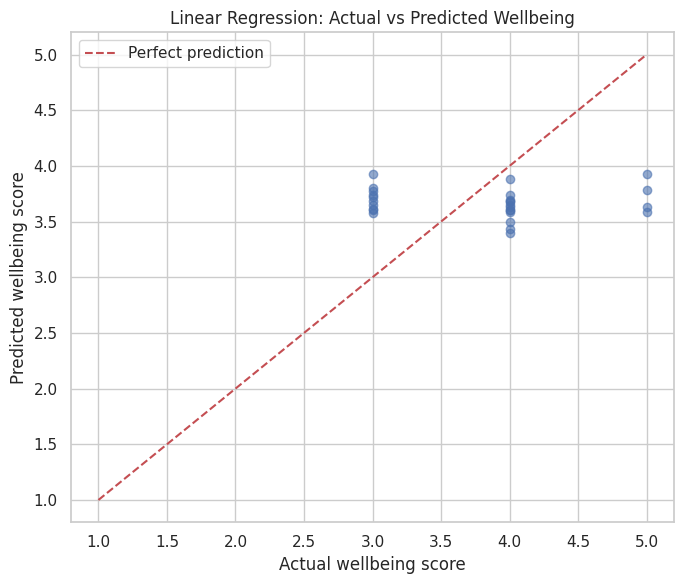

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Features (X) = what was measured about the environment; target (y) = what we want to predict
features = ['sound_level_score', 'foot_traffic_score', 'trees_presence_score', 'birds_count', 'insects_count']
target = 'wellbeing_rating_score'

X = encoded_df[features]
y = encoded_df[target]

# Hold back 20% of the rows to test the model on data it has not seen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model, then predict on the unseen test rows
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

# Evaluate
baseline_mae = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))
print(f"R-squared: {r2_score(y_test, y_pred):.3f}")
print(f"Mean absolute error (MAE): {mean_absolute_error(y_test, y_pred):.3f}")
print(f"Root mean squared error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
print(f"Baseline MAE (always guessing the average): {baseline_mae:.3f}")

# Coefficients: change in predicted wellbeing score for a 1-unit increase in each feature
coef_table = pd.DataFrame({'feature': features, 'coefficient': lin_reg.coef_}).sort_values('coefficient')
display(coef_table.round(3))

# Predicted vs actual
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([1, 5], [1, 5], 'r--', label='Perfect prediction')
plt.xlabel('Actual wellbeing score')
plt.ylabel('Predicted wellbeing score')
plt.title('Linear Regression: Actual vs Predicted Wellbeing')
plt.legend()
plt.tight_layout()
plt.show()

## Learning Process: Linear Regression

X is the table of inputs and y is the single column to predict. The model learns how X relates to y.

---

train_test_split(..., test_size=0.2, random_state=42) randomly sets aside 20% of rows as a test set. The model learns from the other 80% and is then marked on rows it never saw. random_state=42 makes the split the same every time I run it.

---

fit(X_train, y_train) this is the learning step. It finds the best weight (coefficient) for each feature plus a starting value (intercept).

---

predict(X_test) applies those weights to the test rows to produce predicted wellbeing scores.

---

Evaluation:
R-squared is the share of the variation in wellbeing the model explains. 1 is perfect, 0 is no better than guessing the average, and it can go negative. MAE is on average, how many score points the prediction is off by. RMSE is like MAE but it punishes big misses more. Baseline MAE is the error if I always guessed the average wellbeing score. The model is only useful if it beats this.
Coefficients are a positive number means that a higher feature value goes with a higher predicted wellbeing score. A negative number means the opposite.

The way I learnt this was I printed X.head(), y.head() and the shapes of the train and test sets to see exactly what the model receives, then printed lin_reg.coef_ and lin_reg.intercept_ to see what it learned.

There were limitations such as the test set is small meaning that the scores can change a lot with a different random_state.Wellbeing is a 1-5 rating treated as a number, and the gaps between ratings may not be equal. The features are only a small slice of what affects wellbeing.

### Results

104 were used for training and 27 for testing. R-squared on the test set is -0.082. A negative value means the model did worse than simply predicting the average wellbeing score every time. MAE is 0.633, which is higher than the baseline MAE of 0.601, and RMSE is 0.712. Even on the training data R-squared is only 0.032. Coefficients so the trees were +0.138, foot traffic +0.116, insects +0.018, birds +0.010, sound level -0.100. The signs suggest that louder places go with slightly lower wellbeing and more trees with slightly higher, but these effects are tiny and should not be trusted because the model fails to beat the baseline.

---

My Interpretation of the data is that these five environmental measurements cannot predict wellbeing. That matches the weak correlations I saw during exploration. This is still a valid finding: a model that does not beat the baseline tells me the features do not explain wellbeing here.

I'd say that wellbeing is a personal rating and is very subjective because the test set is only 27 rows, so the result is pretty noisy and many things I did not include like the weather, who recorded it, how the person felt that day probably matter more.

If I could improve the data set I would've added weather, handle the missing temperature values and add temperature, try a different random_state or cross-validation to check the result is stable, and compare with a different target such as stress.

# K-Means Clustering

**Question:** do the observations fall into natural groups (for example quiet green spots with high wellbeing versus busy noisy spots with higher stress)?

K-Means is unsupervised: I give it no target. It groups similar rows together using their distance from each other. I use six columns: four about the environment and two about experience.

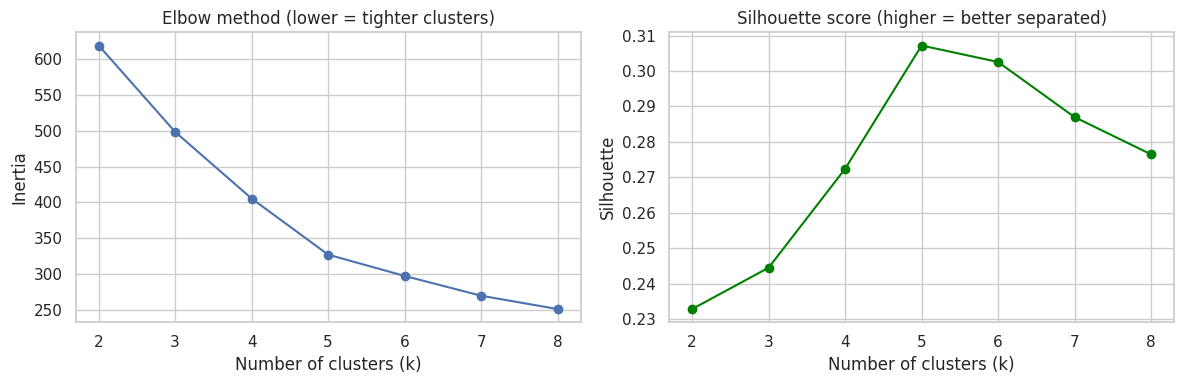

Best k by silhouette score: 5


In [15]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

cluster_features = ['sound_level_score', 'foot_traffic_score', 'trees_presence_score', 'birds_count', 'wellbeing_rating_score', 'stress_rating_score']

# Scale every feature to mean 0 and spread 1 (K-Means uses distance, so big numbers like birds_count would otherwise dominate)
X_scaled = StandardScaler().fit_transform(encoded_df[cluster_features])

# Try k = 2 to 8 clusters and record two quality measures for each
k_values = list(range(2, 9))
inertias = []
silhouettes = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker='o')
axes[0].set_title('Elbow method (lower = tighter clusters)')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[1].plot(k_values, silhouettes, marker='o', color='green')
axes[1].set_title('Silhouette score (higher = better separated)')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

best_k = k_values[int(np.argmax(silhouettes))]
print(f"Best k by silhouette score: {best_k}")

cluster
0     4
1    29
2    28
3    39
4    31
Name: count, dtype: int64


,sound_level_score,foot_traffic_score,trees_presence_score,birds_count,wellbeing_rating_score,stress_rating_score
cluster,,,,,,
0,1.00,1.25,1.75,14.25,4.00,2.00
1,2.45,2.45,1.93,2.38,3.69,2.31
2,1.36,1.14,0.86,2.00,3.79,2.07
3,1.49,1.03,2.00,1.26,4.28,1.41
4,1.61,1.06,1.97,1.19,2.87,3.13


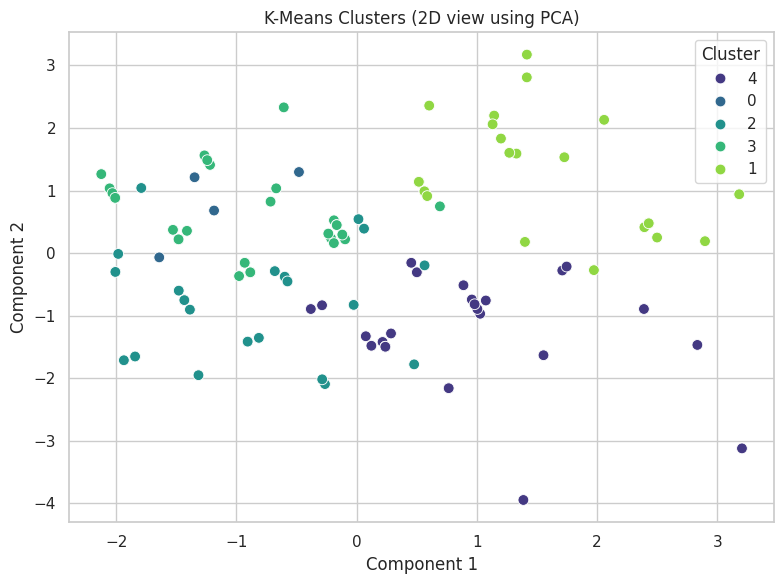

cluster,0,1,2,3,4
location,,,,,
L01 MainEntrance,0,10,2,5,5
L02 LibraryGreen,0,8,0,4,2
L03 LowerSidePathiHub,0,1,3,3,2
L04 PathFrontiHub,0,8,0,5,5
L05 GreenFrontSportsCentre,0,1,0,11,7
L06 HedgingBehindSportsCentre,4,1,9,8,5
L07 CarParkNearSportsCentre,0,0,8,2,5
L08 AccessRoadNearSportsCentre,0,0,6,1,0


In [16]:
from sklearn.decomposition import PCA
import seaborn as sns

# Fit the final model using the chosen k
final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_df = encoded_df[['location'] + cluster_features].copy()
cluster_df['cluster'] = final_km.fit_predict(X_scaled)

# How many observations are in each cluster
print(cluster_df['cluster'].value_counts().sort_index())

# Cluster profile: the average of each feature inside each cluster (original units)
display(cluster_df.groupby('cluster')[cluster_features].mean().round(2))

# Squash the 6 features down to 2 so the clusters can be drawn
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=cluster_df['cluster'].astype(str), palette='viridis', s=60)
plt.title('K-Means Clusters (2D view using PCA)')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# Which locations do the clusters come from?
display(pd.crosstab(cluster_df['location'], cluster_df['cluster']))

## Learning Process: K-Means Clustering

StandardScaler rescales each column to have an average of 0 and a similar spread. K-Means works by measuring distances, so without scaling a column with big numbers (birds_count) would outweigh a column that only goes from 1 to 3.

---

KMeans(n_clusters=k) picks k centre points, assigns every row to its nearest centre, moves each centre to the middle of its rows, and repeats until nothing changes. random_state and n_init make the result repeatable.

---

The total distance from each row to its cluster centre. It always falls as k rises, so I look for the "elbow" where improvement slows.
Silhouette score just displays from -1 to 1, how well each row fits its own cluster compared with the next nearest one. Higher is better, and best_k is the k with the highest score.

---

Cluster profile groupby('cluster').mean() juat shows the average of each feature in each cluster. This is how I give each cluster a meaning, because K-Means only gives them numbers.

---

PCA plot I cannot draw 6 dimensions, so PCA squashes them into 2 while keeping as much of the pattern as possible. Clusters that look separate here are clearly different.

---

Crosstabs are counts how many rows from each location landed in each cluster.

---

I changed best_k by hand for example to 3 and 4 and reran the profile table to see how the groups changed, and I printed X_scaled[:5] to see what scaling did to the numbers.

---

There were a few limitations such as the silhouette score only measures mathematical separation, not whether the groups make sense. Anothering being the clusters change with the features I choose. And K-Means always produces clusters, even when the data has no real groups.

### Results

The silhouette scores for k = 2 to 8 were 0.23, 0.25, 0.27, 0.31, 0.30, 0.29 and 0.28. The best is k = 5 0.307, but k = 6 is almost as good 0.303. The elbow plot has no sharp bend, inertia falls steadily from 619 to 251. A silhouette around 0.3 means the groups are only weakly to moderately separated. The 2D PCA picture only captures about 55% of the variation 31% and 25%, so the clusters overlapping in the picture is to be expected.

My interpertation with clustering is where clusters 3 and 4 have almost the same environment but opposite experiences. So a decent looking environment does not guarantee a good experience, which fits the weak Linear Regression result I had. The busy and loud places like cluster 1 have a little more stress, which fits the small sound and stress link.

---

There was one huge limitation where I included the wellbeing and stress as clustering features, so the clusters are partly split by how people felt rather than by the environment alone. A stronger test would cluster using only the environment columns, then check the average wellbeing and stress in each cluster.